In [1]:
import numpy as np
from PIL import Image
import cv2
import matplotlib.pylab as plt

# Exercise Set 1
## Loading and Displaying Images

In [3]:
cat_cv2 = cv2.imread("cat.jpg") #Loading image with OpenCV
cat_pil = Image.open("cat.jpg") #Loading image wit Pillow

In [4]:
cat_array = np.asarray(Image.open("cat.jpg"))
cat_array.shape #prints array

(183, 275, 3)

In [5]:
cat_mpl = plt.imread("cat.jpg") #numpy array

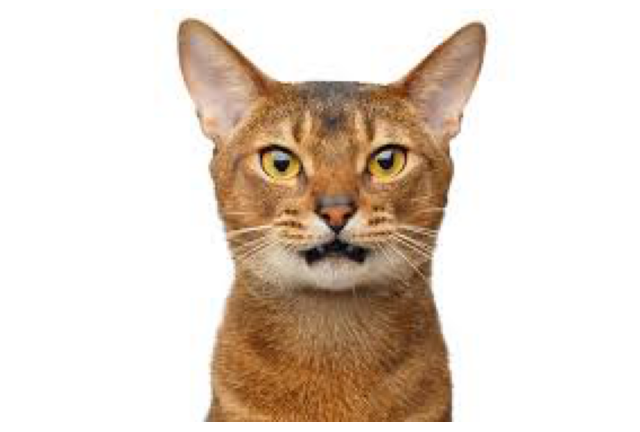

In [6]:
fig, ax = plt.subplots(figsize=(8,8))
ax.imshow(Image.open("cat.jpg"))
ax.axis("off") 
plt.show()

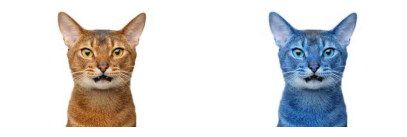

In [7]:
fig, axs = plt.subplots(1,2, figsize=(5,5))
axs[0].imshow(Image.open("cat.jpg")) #PIL
axs[1].imshow(cv2.imread("cat.jpg")) #OpenCV
axs[0].axis("off"), axs[1].axis("off")
plt.show()            

In [8]:
cat_array2 = np.asarray(cv2.imread("cat.jpg"))
print("OpenCV array shape: ",cat_array2.shape)
print("Pillow array shape: ",cat_array.shape)

OpenCV array shape:  (183, 275, 3)
Pillow array shape:  (183, 275, 3)


## 2. Image Properties and Colos Spaces

In [10]:
dog_cv2 = cv2.imread("dog.jpg") #Loading dog image with OpenCV
dog_pil = Image.open("dog.jpg") #Loadin dog image wit Pillow

In [11]:
print("CV2 dimensions" ,dog_cv2.shape)
print("PIL dimensions" ,dog_pil.size) #PIL doesn't have attribute shape, must use size
dog_pil_array = np.array(dog_pil)
print("Pil dimensions with array:", dog_pil_array.shape)

CV2 dimensions (183, 275, 3)
PIL dimensions (275, 183)
Pil dimensions with array: (183, 275, 3)


PIL is PGB and OpenCV is BGR

In [13]:
from PIL import ImageOps

dog_pil_gray = ImageOps.grayscale(dog_pil) #Convert PIL to gray
# dog_gray = dog_pil.convert('L') also good choice for PIL to convert grayscale
dog_cv2_gray = cv2.cvtColor(dog_cv2, cv2.COLOR_BGR2GRAY) #Convert CV2 to gray


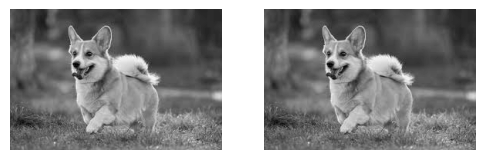

In [14]:
#Showing the pictures
fig, axs = plt.subplots(1,2, figsize=(6,6))
axs[0].imshow(dog_pil_gray, cmap='gray') #PIL 
axs[1].imshow(dog_cv2_gray, cmap='gray') #OpenCV
axs[0].axis("off"), axs[1].axis("off")
plt.show()

In [15]:
dog_cv2_hsv = cv2.cvtColor(dog_cv2, cv2.COLOR_BGR2HSV)

In [16]:
dog_cv2_rbg = cv2.cvtColor(dog_cv2, cv2.COLOR_BGR2RGB)

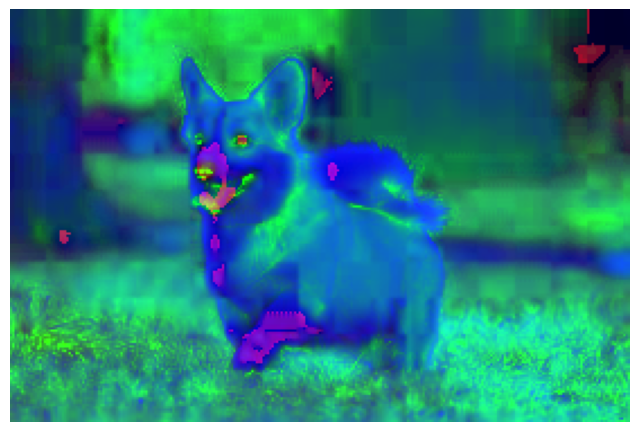

In [17]:
#Showing the OpenCV in HSV, I didn't find how to convert PIL 
fig, ax = plt.subplots(figsize=(8,8))
ax.imshow(dog_cv2_hsv) #OpenCV
ax.axis("off")
plt.show()

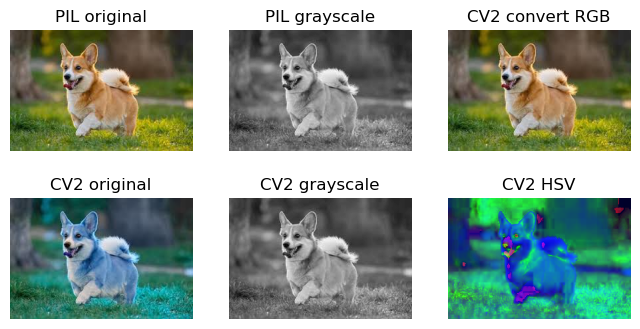

In [18]:
fig, axs = plt.subplots(2,3, figsize=(8,4))
axs[0,0].imshow(dog_pil) #PIL 
axs[0,1].imshow(dog_pil_gray, cmap='gray') #PIL 
axs[0,2].imshow(dog_cv2_rbg) #PIL 
axs[1,0].imshow(dog_cv2) #OpenCV
axs[1,1].imshow(dog_cv2_gray, cmap='gray') #OpenCV
axs[1,2].imshow(dog_cv2_hsv) #OpenCV
axs[0,0].set_title("PIL original"),axs[0,1].set_title("PIL grayscale")
axs[0,2].set_title("CV2 convert RGB"), axs[1,0].set_title("CV2 original")
axs[1,1].set_title("CV2 grayscale"), axs[1,2].set_title("CV2 HSV")
axs[0,0].axis("off"), axs[0,1].axis("off"),axs[0,2].axis("off")
axs[1,0].axis("off"),axs[1,1].axis("off"), axs[1,2].axis("off")
plt.show()

## 3. Resizing and Cropping

In [20]:
cat_cv2 = cv2.imread("cat.jpg") #Loading image with OpenCV
cat_pil = Image.open("cat.jpg") #Loading image wit Pillow
new_height = 50
new_width = 50

In [21]:
cat_pil_resize = cat_pil.resize((new_width,new_height)) #resize image to 50x50 pixels
resize_cat_cv2 = cv2.resize(cat_cv2, (new_width, new_height)) #resize image to 50x50 pixels

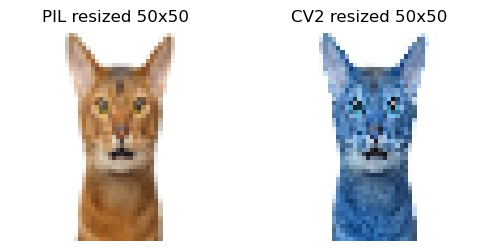

In [22]:
#Resized images of PIL and CV2
fig, axs = plt.subplots(1,2, figsize=(6,6))
axs[0].imshow(cat_pil_resize) #PIL 
axs[1].imshow(resize_cat_cv2) #OpenCV
axs[0].set_title("PIL resized 50x50")
axs[1].set_title("CV2 resized 50x50")
axs[0].axis("off"), axs[1].axis("off")
plt.show()

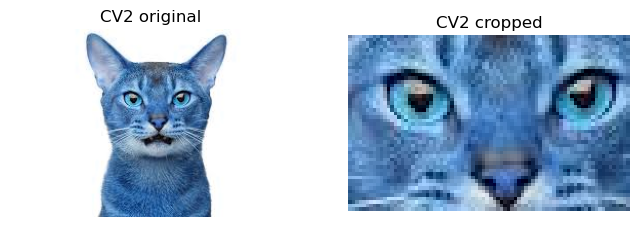

In [23]:
#Cropping images
x_start, y_start, x_end, y_end = 100, 50, 180, 100
cropped_cat_cv2 = cat_cv2[y_start:y_end, x_start:x_end]

fig, axs = plt.subplots(1,2, figsize=(8,8))
axs[0].imshow(cat_cv2) #PIL 
axs[1].imshow(cropped_cat_cv2) #OpenCV
axs[0].set_title("CV2 original")
axs[1].set_title("CV2 cropped")
axs[0].axis("off"), axs[1].axis("off")
plt.show()

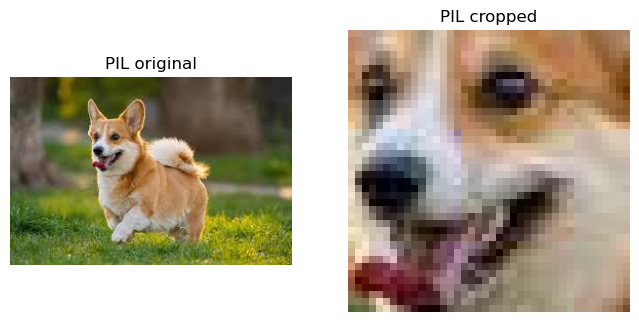

In [24]:
#Cropping PIL image
area = (80, 50, 120, 90)
cropped_dog_pil = dog_pil.crop(area)
fig, axs = plt.subplots(1,2, figsize=(8,8))
axs[0].imshow(dog_pil) #PIL 
axs[1].imshow(cropped_dog_pil) #OpenCV
axs[0].set_title("PIL original")
axs[1].set_title("PIL cropped")
axs[0].axis("off"), axs[1].axis("off")
plt.show()

## 4. Saving Images

In [26]:
cv2.imwrite("saved_gray_dog.jpg", dog_cv2_gray)

True

In [27]:
dog_pil_gray.save("pil_saved_gray_dog.jpg")

# Exercise Set 2: Image Processing Techniques

## 5. Image smooting:

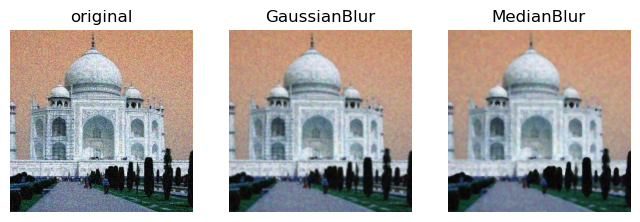

In [30]:
#OpenCV , GaussianBlur and medianBlur
img1 = cv2.imread("noisy_pic.jpg")
blur_cv2 = cv2.GaussianBlur(img1, (5,5), 0)
medianblur_cv2 = cv2.medianBlur(img1, 5)
fig, axs = plt.subplots(1,3, figsize=(8,8))
axs[0].imshow(img1) #PIL 
axs[1].imshow(blur_cv2) #GaussianBlur
axs[2].imshow(medianblur_cv2) #MedianBlur
axs[0].set_title("original")
axs[1].set_title("GaussianBlur")
axs[2].set_title("MedianBlur")

axs[0].axis("off"), axs[1].axis("off"), axs[2].axis("off")
plt.show()


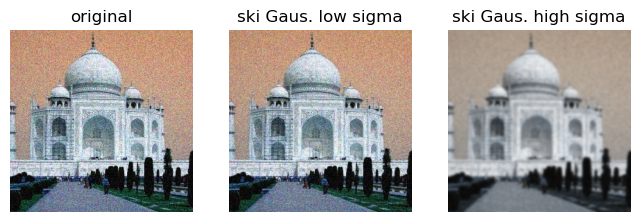

In [31]:
import skimage


ski_img1 = skimage.filters.gaussian(img1, sigma=0.4)#low sigma = mild smooting
ski_img2 = skimage.filters.gaussian(img1, sigma=1.8)#High sigma = more smooting
fig, axs = plt.subplots(1,3, figsize=(8,8))
axs[0].imshow(img1)
axs[1].imshow(ski_img1)
axs[2].imshow(ski_img2)
axs[0].set_title("original")
axs[1].set_title("ski Gaus. low sigma")
axs[2].set_title("ski Gaus. high sigma")
axs[0].axis("off"), axs[1].axis("off"), axs[2].axis("off")
plt.show()

In my opinion is that OpenCV GaussianBlur is the most smoothing tool.
MedianBlur is also very good, but details are more blurrier that with Gaussian blur.
Skimage's GaussianBlur fade out colors.


## 6. Edge Detection

In [34]:
gray1 = cv2.imread("saved_gray_dog.jpg")

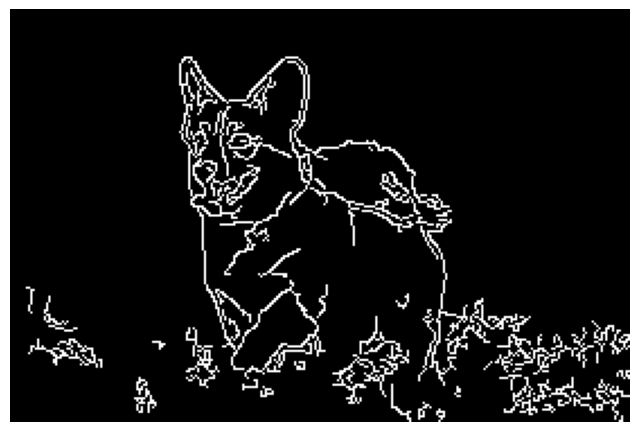

In [35]:
edges = cv2.Canny(gray1,100,300)
fig,ax = plt.subplots(figsize=(8,8))
ax.imshow(edges, cmap='gray')
ax.axis("off")
plt.show()

#### 7. Thresholding

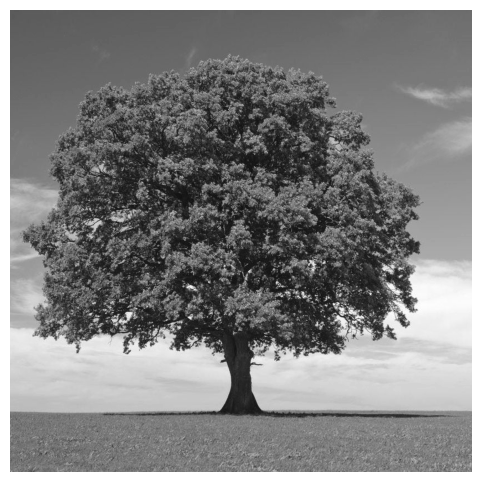

In [37]:
gray2 = cv2.imread("tree.jpg", cv2.IMREAD_GRAYSCALE)
fig,ax = plt.subplots(figsize=(6,6))
ax.imshow(gray2, cmap='gray')
ax.axis("off")
plt.show()

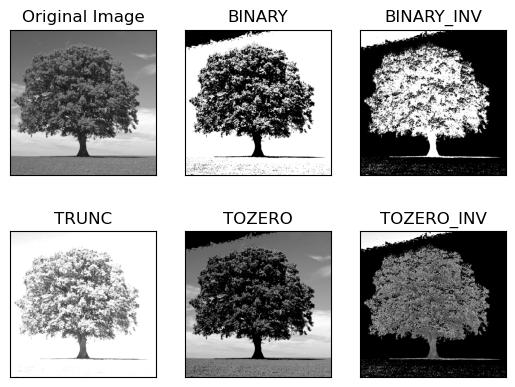

In [38]:
val1, val2 = 100,200 #val1 = threshold and val2 = max value
#black = 0, white = 255
ret,thresh1 = cv2.threshold(gray2,val1,val2, cv2.THRESH_BINARY) #pixels>val1 -> val2, else = 0
ret,thresh2 = cv2.threshold(gray2,val1,val2,cv2.THRESH_BINARY_INV)#pixels>val1 -> 0, else = val2
ret,thresh3 = cv2.threshold(gray2,val1,val2,cv2.THRESH_TRUNC) #pixels>val1 -> val1, else unchange
ret,thresh4 = cv2.threshold(gray2,val1,val2,cv2.THRESH_TOZERO) #pixels<val1 -> 0, else unchange
ret,thresh5 = cv2.threshold(gray2,val1,val2,cv2.THRESH_TOZERO_INV) #pixels>val1 -> 0, else unchange

titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [gray2, thresh1, thresh2, thresh3, thresh4, thresh5]

for i in range(6):
    plt.subplot(2,3,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

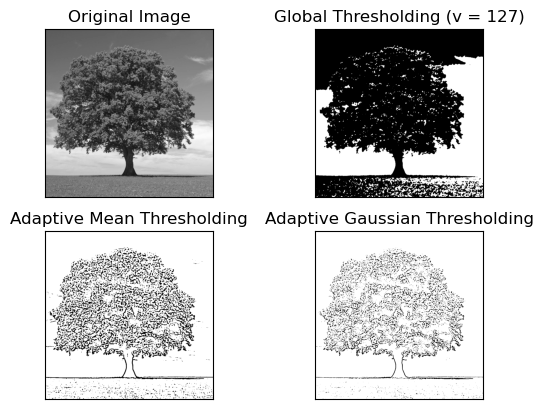

In [39]:
gray2_blur = cv2.medianBlur(gray2,5) #removes the noise and does the average more cleaner

blocksize = 9 # 9x9
C_value = 7 # this value substracted from means

# THRESH_BINARY, threshold = pixels > 127 -> 255 (white)
ret,th1 = cv2.threshold(gray2_blur, 127,255,cv2.THRESH_BINARY) 

# ADAPTIVE_THRESH_MEAN_C, threshold = local area mean minus C, pixels > threshold -> 255
th2 = cv2.adaptiveThreshold(gray2_blur,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
                            cv2.THRESH_BINARY,blocksize,C_value) #

#ADAPTIVE_THRESH_GAUSSIAN_C, same as mean, but average is gaussian-weighted sum
th3 = cv2.adaptiveThreshold(gray2_blur,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
                            cv2.THRESH_BINARY,blocksize,C_value)

titles = ['Original Image', 'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
images = [gray2, th1, th2, th3]

for i in range(4):
    plt.subplot(2,2,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

## 8. Histograms

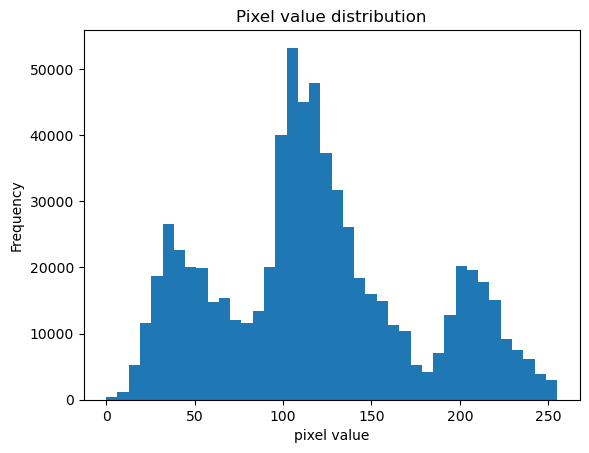

In [41]:
import pandas as pd

pd.Series(gray2.flatten()).plot(kind='hist', bins=40,title='Pixel value distribution')
plt.xlabel('pixel value')
plt.show()

# Exercise Set 3: Feature Detection

## 9. Corner Detection

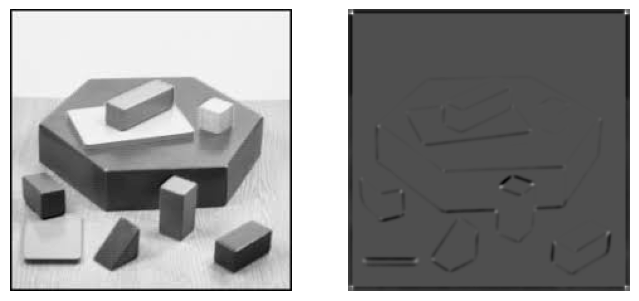

In [44]:
corner = cv2.imread("corner.jpg", cv2.IMREAD_GRAYSCALE)
corner = np.float32(corner) #Harris usually needs float type

blocksize = 3 #area size, small value finds smaller details
sobelsize = 9 #gradient size, small value(3) is more precise, big 5-> less precise
k = 0.04 # small value finds more corners, big 0.06-> finds just clear corners
harris = cv2.cornerHarris(corner, blocksize, sobelsize, k)
#harris = cv2.dilate(harris,None) // This enlarges the detected corners for better visibility

fig, axs = plt.subplots(1,2, figsize=(8,8)) 
axs[0].imshow(corner, cmap='gray')
axs[1].imshow(harris, cmap='gray')
axs[0].axis('off'), axs[1].axis('off')
plt.show()

# Exercise Set 4: Object Detection


## 10. Object Detection with Haar Cascades

In [47]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_alt.xml')
if face_cascade.empty():
    print("Error: cascade not loaded!")

In [48]:
face_cascade.empty() #check that the cascade is loaded

False

In [49]:
def adjusted_detect_face(img):
    img_copy = img.copy()
    #detectMustiScale detects faces at different scale
    #scaleFactor controls image scaling
    faces = face_cascade.detectMultiScale(img_copy, scaleFactor=1.1, minNeighbors=5)

    for (x, y, w, h) in faces:
        cv2.rectangle(img_copy, (x, y), (x + w, y + h), (255, 255, 255),5)
    #rectangle draw bow around detected faces
    return img_copy

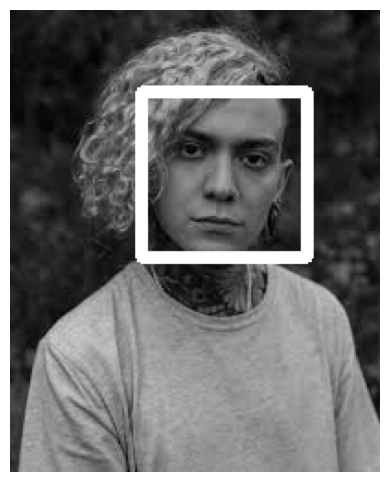

In [50]:
lorna = cv2.imread('lorna.jpg', cv2.IMREAD_GRAYSCALE)

face = adjusted_detect_face(lorna)
fig,ax = plt.subplots(figsize=(6,6))
ax.imshow(face, cmap='grey')
ax.axis("off")
plt.show()